In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

print("Real news articles:", len(real))
print("Fake news articles:", len(fake))

Real news articles: 21417
Fake news articles: 23481


In [3]:
real["title"] = real["title"].fillna("")
real["text"] = real["text"].fillna("")

fake["title"] = fake["title"].fillna("")
fake["text"] = fake["text"].fillna("")

real["Category"] = "Real News"
fake["Category"] = "Fake News"

news = pd.concat(
    [
        real[["title", "text", "Category"]],
        fake[["title", "text", "Category"]]
    ],
    ignore_index=True
)

news.head()

,title,text,Category
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,Real News
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,Real News
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,Real News
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,Real News
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,Real News


In [4]:
# Sensational Words and Phrases
patterns = {
    "Sensational Words": (
        r"\b(shocking|unbelievable|outrageous|horrifying|"
        r"astonishing|incredible|scandalous)\b"
    ),

    "Exaggerated Words": (
        r"\b(unprecedented|greatest|worst|massive|"
        r"always|never|ultimate|devastating)\b"
    ),

    "Misleading Phrases": (
        r"\b(secret(?:ly)? revealed|you won't believe|"
        r"what they don't want you to know|"
        r"the truth about|cover[\s-]?up|"
        r"hidden truth|shocking truth)\b"
    ),

    "Dramatic Words": (
        r"\b(terrifying|catastrophe|explosive|"
        r"disaster|panic|nightmare|devastation)\b"
    )
}

In [5]:
# Count Sensational Language in Headlines and Articles
for name, pattern in patterns.items():
    news["Headline_" + name] = (
        news["title"].str.lower().str.count(pattern)
    )

    news["Article_" + name] = (
        news["text"].str.lower().str.count(pattern)
    )

news[
    ["title", "Category",
     "Headline_Sensational Words",
     "Article_Sensational Words"]
].head()

,title,Category,Headline_Sensational Words,Article_Sensational Words
0,"As U.S. budget fight looms, Republicans flip t...",Real News,0,0
1,U.S. military to accept transgender recruits o...,Real News,0,0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,Real News,0,0
3,FBI Russia probe helped by Australian diplomat...,Real News,0,0
4,Trump wants Postal Service to charge 'much mor...,Real News,0,0


In [6]:
# Calculate Article Word Counts
news["Article_Word_Count"] = (news["text"].str.findall(r"\b[a-zA-Z]+\b").str.len())

news["Headline_Word_Count"] = (news["title"].str.findall(r"\b[a-zA-Z]+\b").str.len())

news[["Category", "Headline_Word_Count", "Article_Word_Count"]].head()

,Category,Headline_Word_Count,Article_Word_Count
0,Real News,11,747
1,Real News,10,631
2,Real News,11,464
3,Real News,10,386
4,Real News,11,847


In [7]:
# Compare Sensational Language in Both Categories
comparison = []

for category in ["Real News", "Fake News"]:

    data = news[news["Category"] == category]

    total_articles = len(data)
    total_article_words = data["Article_Word_Count"].sum()

    for name in patterns:

        headline_count = data["Headline_" + name].sum()
        article_count = data["Article_" + name].sum()

        comparison.append({
            "Category": category,
            "Language Type": name,
            "Headline Matches per 100 Headlines": (
                headline_count / max(total_articles, 1) * 100
            ),
            "Article Matches per 1000 Words": (
                article_count / max(total_article_words, 1) * 1000
            )
        })

result = pd.DataFrame(comparison)

result.round(3)

,Category,Language Type,Headline Matches per 100 Headlines,Article Matches per 1000 Words
0,Real News,Sensational Words,0.028,0.033
1,Real News,Exaggerated Words,0.280,0.612
2,Real News,Misleading Phrases,0.014,0.008
3,Real News,Dramatic Words,0.229,0.114
4,Fake News,Sensational Words,1.559,0.185
5,Fake News,Exaggerated Words,2.249,1.243
6,Fake News,Misleading Phrases,0.332,0.066
7,Fake News,Dramatic Words,0.767,0.168


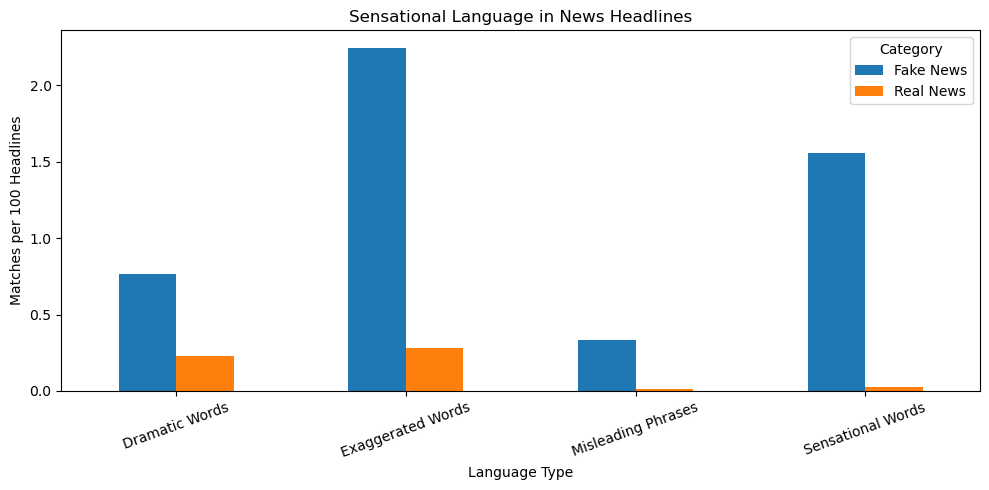

In [8]:
# Sensational Language in Headlines
headline_result = result.pivot(index="Language Type", columns="Category", values="Headline Matches per 100 Headlines")

headline_result.plot(kind="bar", figsize=(10, 5))

plt.title("Sensational Language in News Headlines")
plt.xlabel("Language Type")
plt.ylabel("Matches per 100 Headlines")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

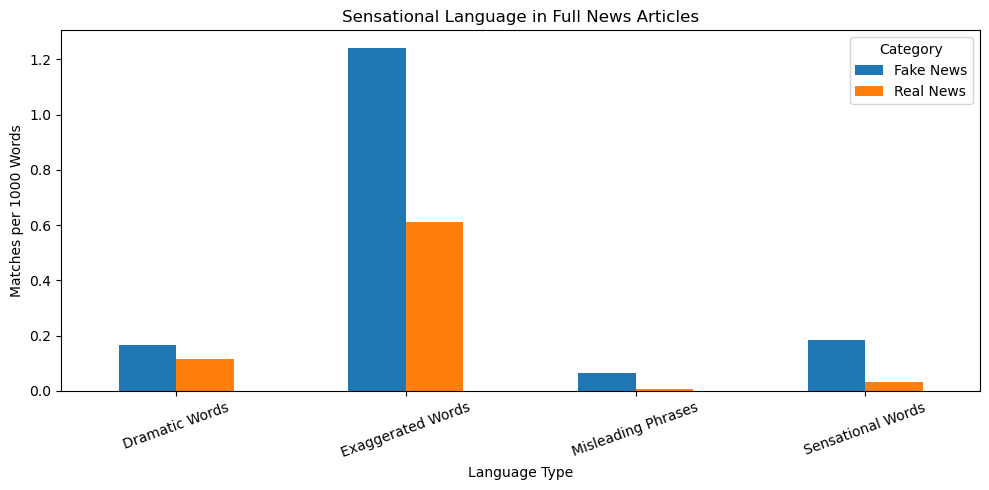

In [9]:
# Sensational Language in Full Articles
article_result = result.pivot(index="Language Type", columns="Category", values="Article Matches per 1000 Words")

article_result.plot(kind="bar", figsize=(10, 5))

plt.title("Sensational Language in Full News Articles")
plt.xlabel("Language Type")
plt.ylabel("Matches per 1000 Words")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [10]:
# Matched Phrases
misleading_pattern = patterns["Misleading Phrases"]

examples = news[news["title"].str.lower().str.contains(misleading_pattern, regex=True, na=False)]

examples[["Category", "title"]].head(15)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_9516\2608458848.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  examples = news[news["title"].str.lower().str.contains(misleading_pattern, regex=True, na=False)]


,Category,title
4287,Real News,White House accuses Russia of Syria chemical a...
10637,Real News,Ousted Michigan lawmakers face felony charges ...
16325,Real News,Russia undermining action against chemical wea...
21679,Fake News,Trump LOSES HIS SH*T On Twitter Because The M...
21804,Fake News,Cowardly ESPN Won’t Stand Up For Black Report...
23407,Fake News,Fox News Frantically Tries To Cover Up Trump’...
23481,Fake News,Nixon’s Counsel During Watergate CALLS OUT Tr...
23791,Fake News,COVER UP: Sean Spicer Asked CIA And Top Repub...
24752,Fake News,Trump Throws PETTY Hissy Fit Because Bill Cli...
26498,Fake News,Alabama Republican Governor BUSTED Lying To C...
